<a href="https://colab.research.google.com/github/Ron-Maina/Brain-Tumour-Segmentation-/blob/main/Multi_Region_Brain_Tumour_Segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q "monai[nibabel]"

import os
import re
import json
import time

import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt

import torch
from sklearn.model_selection import train_test_split

import monai
from monai.data import Dataset, DataLoader
from monai.transforms import (
    Compose, LoadImaged, EnsureChannelFirstd, NormalizeIntensityd,
    RandCropByPosNegLabeld, RandFlipd, RandRotated, RandScaleIntensityd, RandShiftIntensityd, EnsureTyped,
)
from monai.networks.nets import UNet, AttentionUnet
from monai.losses import DiceCELoss, DeepSupervisionLoss
from monai.metrics import DiceMetric
from monai.inferers import sliding_window_inference

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# GPU check
print("torch", torch.__version__, "| monai", monai.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
print("CPU cores:", os.cpu_count())

WORK_DIR = "/content/drive/MyDrive/Datasets"
os.makedirs(WORK_DIR, exist_ok=True)
os.chdir(WORK_DIR)


dummy = {"epoch": 0, "state_dict": {}}
torch.save(dummy, os.path.join(WORK_DIR, "checkpoint_test.pt"))
reloaded = torch.load(os.path.join(WORK_DIR, "checkpoint_test.pt"))
print("Checkpoint reload OK:", reloaded["epoch"] == 0)


torch 2.11.0+cu130 | monai 1.6.1
GPU available: True
GPU name: NVIDIA A100-SXM4-40GB
CPU cores: 12
Checkpoint reload OK: True


In [ ]:
# Inspect the zip before extracting anything
import os, zipfile, shutil

ZIP_PATH = "/content/drive/MyDrive/Datasets/archive.zip"

with zipfile.ZipFile(ZIP_PATH) as z:
    infos = z.infolist()
    unpacked = sum(i.file_size for i in infos)
    packed = sum(i.compress_size for i in infos)
    print("entries in zip:", len(infos))
    print(f"unpacked size: {unpacked/1e9:.1f} GB | size inside the zip: {packed/1e9:.1f} GB")
    for i in infos[:12]:
        print("  ", i.filename, f"{i.file_size/1e6:.0f} MB")

free = shutil.disk_usage("/content").free
print(f"free local disk: {free/1e9:.0f} GB")
print("full extraction fits:", unpacked < free * 0.9)

entries in zip: 1274
unpacked size: 111.5 GB | size inside the zip: 7.9 GB
   Task01_BrainTumour/._dataset.json 0 MB
   Task01_BrainTumour/._imagesTr 0 MB
   Task01_BrainTumour/._imagesTs 0 MB
   Task01_BrainTumour/._labelsTr 0 MB
   Task01_BrainTumour/dataset.json 0 MB
   Task01_BrainTumour/imagesTr/._BRATS_001.nii.gz 0 MB
   Task01_BrainTumour/imagesTr/._BRATS_002.nii.gz 0 MB
   Task01_BrainTumour/imagesTr/._BRATS_004.nii.gz 0 MB
   Task01_BrainTumour/imagesTr/._BRATS_006.nii.gz 0 MB
   Task01_BrainTumour/imagesTr/._BRATS_027.nii.gz 0 MB
   Task01_BrainTumour/imagesTr/._BRATS_028.nii.gz 0 MB
   Task01_BrainTumour/imagesTr/._BRATS_115.nii.gz 0 MB
free local disk: 196 GB
full extraction fits: True


In [ ]:
# Convert to nii.gz while reading
import os, time, gzip, shutil, zipfile

LOCAL_ROOT = "/content/dataset"
os.makedirs(LOCAL_ROOT, exist_ok=True)

def wanted(name):
    parts = name.split("/")
    if parts[-1] == "" or parts[-1].startswith("._") or "__MACOSX" in parts:
        return False
    return ("imagesTr" in parts) or ("labelsTr" in parts) or parts[-1] == "dataset.json"

t0, done, skipped = time.time(), 0, 0
with zipfile.ZipFile(ZIP_PATH) as z:
    members = [i for i in z.infolist() if wanted(i.filename)]
    for k, info in enumerate(members):
        out = os.path.join(LOCAL_ROOT, info.filename)
        if info.filename.endswith(".nii"):
            out += ".gz"                      # same data, stored compressed
        if os.path.exists(out) and os.path.getsize(out) > 0:
            skipped += 1                      # a re-run after a disconnect picks up where it stopped
            continue
        os.makedirs(os.path.dirname(out), exist_ok=True)
        tmp = out + ".part"
        with z.open(info) as src:
            if out.endswith(".gz"):
                with gzip.open(tmp, "wb", compresslevel=1) as dst:
                    shutil.copyfileobj(src, dst, 16 * 1024 * 1024)
            else:
                with open(tmp, "wb") as dst:
                    shutil.copyfileobj(src, dst)
        os.replace(tmp, out)                  # a half-written file never keeps its final name
        done += 1
        if done % 25 == 0:
            print(f"{k + 1}/{len(members)} files, {time.time() - t0:.0f} s")

print(f"converted {done}, already there {skipped}, total {len(members)} in {time.time() - t0:.0f} s")
print(f"local size now: {sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(LOCAL_ROOT) for f in fs) / 1e9:.1f} GB")

converted 0, already there 969, total 969 in 0 s
local size now: 5.7 GB


In [ ]:
# Check images against the originals
import tempfile, zipfile, numpy as np, nibabel as nib

N_CHECK = 3
checked = 0
with zipfile.ZipFile(ZIP_PATH) as z:
    originals = [i for i in z.infolist() if wanted(i.filename) and i.filename.endswith(".nii")][:N_CHECK]
    for info in originals:
        with tempfile.NamedTemporaryFile(suffix=".nii") as tmp:
            with z.open(info) as src:
                shutil.copyfileobj(src, tmp, 16 * 1024 * 1024)
            tmp.flush()
            a = nib.load(tmp.name)
            original = a.get_fdata(); original_affine = a.affine
        b = nib.load(os.path.join(LOCAL_ROOT, info.filename + ".gz"))
        same = np.array_equal(original, b.get_fdata()) and np.array_equal(original_affine, b.affine)
        print(os.path.basename(info.filename), "| identical values and affine:", same)
        checked += 1
print("checked", checked, "files")

BRATS_001.nii | identical values and affine: True
BRATS_002.nii | identical values and affine: True
BRATS_003.nii | identical values and affine: True
checked 3 files


In [ ]:
# Check all labels against the originals
import tempfile, zipfile, numpy as np, nibabel as nib

mismatches, bad_values, n = [], [], 0
with zipfile.ZipFile(ZIP_PATH) as z:
    labels = [i for i in z.infolist() if wanted(i.filename) and "labelsTr" in i.filename.split("/") and i.filename.endswith(".nii")]
    for info in labels:
        with tempfile.NamedTemporaryFile(suffix=".nii") as tmp:
            with z.open(info) as src:
                shutil.copyfileobj(src, tmp, 16 * 1024 * 1024)
            tmp.flush()
            a = nib.load(tmp.name)
            original = np.asarray(a.dataobj); original_affine = a.affine
        b = nib.load(os.path.join(LOCAL_ROOT, info.filename + ".gz"))
        copy = np.asarray(b.dataobj)
        if not (np.array_equal(original, copy) and np.array_equal(original_affine, b.affine)):
            mismatches.append(os.path.basename(info.filename))
        if not set(np.unique(copy).tolist()) <= {0, 1, 2, 3}:
            bad_values.append(os.path.basename(info.filename))
        n += 1
print(f"labels checked: {n} | different from original: {len(mismatches)} | values outside 0-3: {len(bad_values)}")
print("differences:", mismatches[:10], "| bad values:", bad_values[:10])

labels checked: 484 | different from original: 0 | values outside 0-3: 0
differences: [] | bad values: []


In [ ]:
# Find DATA_DIR and time one load
DATA_DIR = None
for root, dirs, files in os.walk(LOCAL_ROOT):
    if "imagesTr" in dirs and "labelsTr" in dirs:
        DATA_DIR = root
        break
print("DATA_DIR =", DATA_DIR)
assert DATA_DIR is not None, "imagesTr/labelsTr not found - paste the output of A3 back"

import nibabel as nib
sample = sorted(f for f in os.listdir(os.path.join(DATA_DIR, "imagesTr")) if not f.startswith("._"))[0]
path = os.path.join(DATA_DIR, "imagesTr", sample)
print(sample, f"{os.path.getsize(path)/1e6:.0f} MB on disk")
for attempt in (1, 2):
    t0 = time.time(); arr = nib.load(path).get_fdata(); print(f"load {attempt}: {time.time() - t0:.2f} s, shape {arr.shape}")

DATA_DIR = /content/dataset/Task01_BrainTumour
BRATS_001.nii.gz 13 MB on disk
load 1: 0.47 s, shape (240, 240, 155, 4)
load 2: 0.47 s, shape (240, 240, 155, 4)


### Data Exploration

In [ ]:
import os
import re
import nibabel as nib
import numpy as np

IMAGES_DIR = os.path.join(DATA_DIR, "imagesTr")
LABELS_DIR = os.path.join(DATA_DIR, "labelsTr")

def is_real_file(filename):
    # skip "._" junk files
    return not filename.startswith("._")

def patient_id(filename):
    match = re.match(r"(BRATS_\d+)", filename)
    return match.group(1) if match else None

image_files = {patient_id(f): os.path.join(IMAGES_DIR, f)
               for f in os.listdir(IMAGES_DIR) if is_real_file(f)}
label_files = {patient_id(f): os.path.join(LABELS_DIR, f)
               for f in os.listdir(LABELS_DIR) if is_real_file(f)}
# matched by patient ID, not filename

patient_ids = sorted(set(image_files) & set(label_files))
print(f"Found {len(patient_ids)} patients with both an image and a label file")

missing_labels = set(image_files) - set(label_files)
missing_images = set(label_files) - set(image_files)
if missing_labels:
    print("Image but no label:", sorted(missing_labels))
if missing_images:
    print("Label but no image:", sorted(missing_images))

issues = []
for pid in patient_ids:
    try:
        image = nib.load(image_files[pid])
        label = nib.load(label_files[pid])
    except Exception as error:
        issues.append((pid, f"failed to load: {error}"))
        continue

    if image.shape[-1] != 4:
        issues.append((pid, f"expected 4 channels, got shape {image.shape}"))

    label_classes = set(np.unique(label.get_fdata()))
    if not label_classes.issubset({0, 1, 2, 3}):
        issues.append((pid, f"unexpected label values: {label_classes}"))

print(f"Checked {len(patient_ids)} patients, found {len(issues)} issues")
for pid, problem in issues:
    print(pid, "-", problem)

Found 484 patients with both an image and a label file
Checked 484 patients, found 0 issues


Background                       4,271,154,985 voxels  (98.843%)
Oedema                              31,456,687 voxels  ( 0.728%)
Non-Enhancing Tumour                 8,731,567 voxels  ( 0.202%)
Enhancing Tumour                     9,808,761 voxels  ( 0.227%)


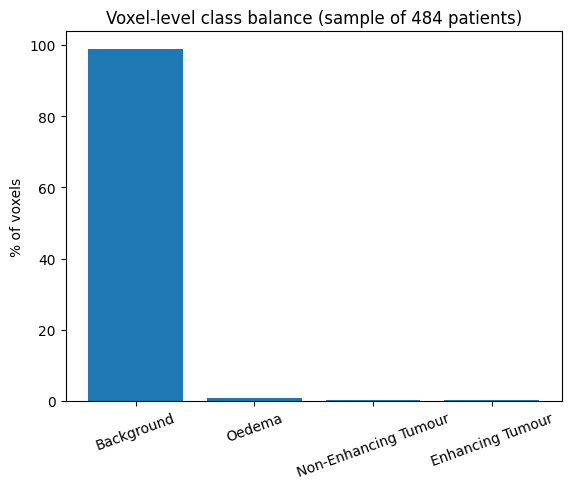

In [ ]:
"""
Voxel-level class balance for the entire dataset based on patient_ids
"""

#0=background, 1=edema, 2=non-enhancing tumor, 3=enhancing tumour.
class_names = ["Background", "Oedema", "Non-Enhancing Tumour", "Enhancing Tumour"]
voxel_counts = np.zeros(4, dtype=np.int64)

sample_size = len(patient_ids)
sample_ids = patient_ids[:sample_size]
for pid in sample_ids:
    label = nib.load(label_files[pid]).get_fdata()
    values, counts = np.unique(label, return_counts=True)
    for v, c in zip(values, counts):
        voxel_counts[int(v)] += c

total_voxels = voxel_counts.sum()
percentages = 100 * voxel_counts / total_voxels

for name, count, pct in zip(class_names, voxel_counts, percentages):
    print(f"{name:30s} {count:>15,d} voxels  ({pct:6.3f}%)")

plt.bar(class_names, percentages)
plt.ylabel("% of voxels")
plt.title(f"Voxel-level class balance (sample of {sample_size} patients)")
plt.xticks(rotation=20)
plt.show()


### Train/val/test split

In [ ]:
from sklearn.model_selection import train_test_split

"""
Two-stage split at patient-level, so no patient's
scans ever appear in more than one of these three sets:
"""

# test set
train_val_ids, test_ids = train_test_split(
    patient_ids, test_size=0.15, random_state=42
)

# train/val set
train_ids, val_ids = train_test_split(
    train_val_ids, test_size=0.15/0.85, random_state=42
)

print(f"train: {len(train_ids)}, val: {len(val_ids)}, test: {len(test_ids)}")

train: 338, val: 73, test: 73


### Preprocessing Pipeline

FLAIR before -> mean:   516.27 std:   211.65   |   after -> mean:  0.000 std:  1.000
T1    before -> mean:   780.63 std:   206.55   |   after -> mean: -0.000 std:  1.000
T1ce  before -> mean:   728.44 std:   239.42   |   after -> mean: -0.000 std:  1.000
T2    before -> mean:   471.84 std:   211.00   |   after -> mean: -0.000 std:  1.000


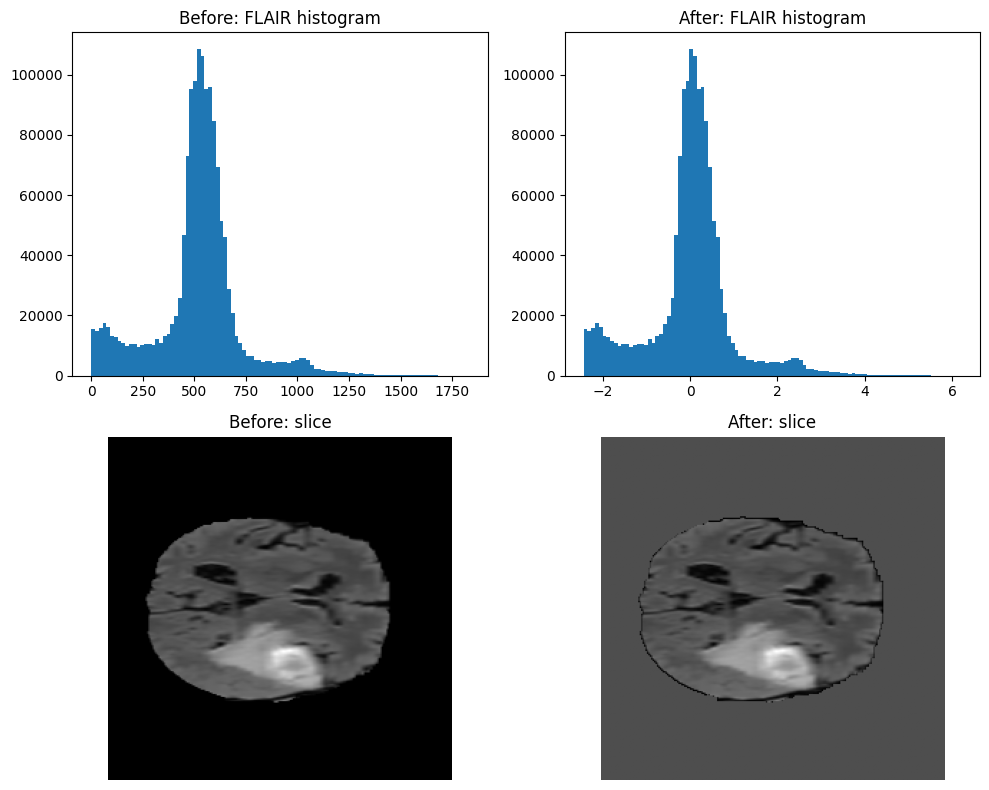

In [ ]:
# Normalization
from monai.transforms import NormalizeIntensity
import numpy as np
import matplotlib.pyplot as plt

# channel_wise: separate mean/std per modality
normalise = NormalizeIntensity(nonzero=True, channel_wise=True)

raw_volume = nib.load(image_files[patient_ids[0]]).get_fdata()   # (H, W, D, 4)
volume_channel_first = np.moveaxis(raw_volume, -1, 0)             # (4, H, W, D)

normalised = normalise(volume_channel_first.copy())

# modality: 0=FLAIR, 1=T1w, 2=T1ce (t1gd), 3=T2w
modality_names = ["FLAIR", "T1", "T1ce", "T2"]
for i, name in enumerate(modality_names):
    before = volume_channel_first[i]
    after = normalised[i]
    print(f"{name:5s} before -> mean: {before[before > 0].mean():8.2f} std: {before[before > 0].std():8.2f}"
          f"   |   after -> mean: {after[after != 0].mean():6.3f} std: {after[after != 0].std():6.3f}")

# visualise one modality (FLAIR)
mod_idx = 0
before_mod = volume_channel_first[mod_idx]
after_mod = normalised[mod_idx]
slice_idx = before_mod.shape[-1] // 2

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes[0, 0].hist(before_mod[before_mod > 0].ravel(), bins=100)
axes[0, 0].set_title(f"Before: {modality_names[mod_idx]} histogram")
axes[0, 1].hist(after_mod[after_mod != 0].ravel(), bins=100)
axes[0, 1].set_title(f"After: {modality_names[mod_idx]} histogram")
axes[1, 0].imshow(before_mod[..., slice_idx], cmap="gray")
axes[1, 0].set_title("Before: slice"); axes[1, 0].axis("off")
axes[1, 1].imshow(after_mod[..., slice_idx], cmap="gray")
axes[1, 1].set_title("After: slice"); axes[1, 1].axis("off")
plt.tight_layout()
plt.show()

### Dataset/Dataloader Design

In [ ]:
def make_data_dicts(ids):
    return [
        {"image": image_files[pid], "label": label_files[pid]}
        for pid in ids
    ]

train_files = make_data_dicts(train_ids)
val_files   = make_data_dicts(val_ids)
test_files  = make_data_dicts(test_ids)

ROTATION_DEG = 15.0

def make_train_transforms(rotation_deg=ROTATION_DEG, intensity=0.1):
    # rotation_deg=0 and intensity=0 (crop and flip only)
    steps = [
        LoadImaged(keys=["image", "label"]),
        EnsureChannelFirstd(keys=["image"], channel_dim=-1),
        EnsureChannelFirstd(keys=["label"], channel_dim="no_channel"),
        NormalizeIntensityd(keys=["image"], channel_wise=True, nonzero=True),
        RandCropByPosNegLabeld(
            keys=["image", "label"],
            label_key="label",
            spatial_size=(96, 96, 96),
            pos=1, neg=1,
            num_samples=2,
        ),
        RandFlipd(keys=["image", "label"], spatial_axis=[0], prob=0.5),
    ]
    if rotation_deg > 0:
        angle = rotation_deg * np.pi / 180   # convert to radians
        # image and label rotate together; the image is interpolated smoothly, the label with
        # nearest-neighbour so it keeps whole class ids
        steps.append(RandRotated(keys=["image", "label"], range_x=angle, range_y=angle, range_z=angle,
                                 prob=0.5, mode=("bilinear", "nearest"), padding_mode="zeros"))
    if intensity > 0:
        # intensity changes touch the image only, never the label
        steps += [RandScaleIntensityd(keys=["image"], factors=intensity, prob=0.5),
                  RandShiftIntensityd(keys=["image"], offsets=intensity, prob=0.5)]
    steps.append(EnsureTyped(keys=["image", "label"]))
    return Compose(steps)

train_transforms = make_train_transforms()

# val/test: no cropping or augmentation, deterministic
eval_transforms = Compose([
    LoadImaged(keys=["image", "label"]),
    EnsureChannelFirstd(keys=["image"], channel_dim=-1),
    EnsureChannelFirstd(keys=["label"], channel_dim="no_channel"),
    NormalizeIntensityd(keys=["image"], channel_wise=True, nonzero=True),
    EnsureTyped(keys=["image", "label"]),
])

train_ds = Dataset(data=train_files, transform=train_transforms)
val_ds   = Dataset(data=val_files,   transform=eval_transforms)
test_ds  = Dataset(data=test_files,  transform=eval_transforms)

train_loader = DataLoader(train_ds, batch_size=2, shuffle=True,  num_workers=8)
# batch_size=1: full-size volumes, one at a time via sliding-window inference
val_loader  = DataLoader(val_ds,  batch_size=1, shuffle=False, num_workers=8)
test_loader = DataLoader(test_ds, batch_size=1, shuffle=False, num_workers=8)

def make_train_loader(rotation_deg=ROTATION_DEG, intensity=0.1):
    # a fresh training loader with the given augmentation strength
    ds = Dataset(data=train_files, transform=make_train_transforms(rotation_deg, intensity))
    return DataLoader(ds, batch_size=2, shuffle=True, num_workers=8)

In [ ]:
print(type(train_loader), type(val_loader), type(test_loader))
batch = next(iter(train_loader))
print(batch["image"].shape, batch["label"].shape)

<class 'monai.data.dataloader.DataLoader'> <class 'monai.data.dataloader.DataLoader'> <class 'monai.data.dataloader.DataLoader'>
torch.Size([4, 4, 96, 96, 96]) torch.Size([4, 1, 96, 96, 96])


### CNN/Segmentation Model Implementation

#### Baseline 3D U-Net

In [ ]:
DROPOUT = 0.1

def build_unet(dropout=DROPOUT):
    return UNet(
        spatial_dims=3,
        in_channels=4,
        out_channels=4,
        channels=(16, 32, 64, 128, 256),
        strides=(2, 2, 2, 2),
        num_res_units=2,
        dropout=dropout,
    ).to(device)

baseline_model = build_unet()

# sanity check: dummy batch through the model
with torch.no_grad():
    dummy_input = torch.zeros(1, 4, 96, 96, 96).to(device)
    dummy_output = baseline_model(dummy_input)
    print("Output shape:", dummy_output.shape)

Output shape: torch.Size([1, 4, 96, 96, 96])


#### Training loop

In [ ]:
def save_checkpoint(path, model, optimizer, scheduler, epoch, history, run_name):
    # checkpoint
    tmp = path + ".tmp"
    torch.save({
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
        "epoch": epoch,
        "history": history,
        "run_name": run_name,
    }, tmp)
    os.replace(tmp, path)

def train_model(model, train_loader, val_loader, num_epochs, run_name,
                lr=1e-4, weight_decay=1e-5, lambda_ce=1.0, save_path=None,
                freeze_params=None, unfreeze_at_epoch=None, deep_supervision=False):
    loss_function = DiceCELoss(to_onehot_y=True, softmax=True, lambda_ce=lambda_ce)
    if deep_supervision:
        loss_function = DeepSupervisionLoss(loss_function)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)

    history = {"train_loss": [], "val_loss": []}
    start_epoch = 0

    # resume if a checkpoint for this run already exists
    if save_path and os.path.exists(save_path):
        ckpt = torch.load(save_path, map_location=device)
        if ckpt["run_name"] != run_name:
            raise ValueError(f"{save_path} belongs to run '{ckpt['run_name']}', not '{run_name}'")
        model.load_state_dict(ckpt["model"])
        optimizer.load_state_dict(ckpt["optimizer"])
        scheduler.load_state_dict(ckpt["scheduler"])
        history = ckpt["history"]
        start_epoch = ckpt["epoch"]
        print(f"[{run_name}] resuming after epoch {start_epoch}/{num_epochs}")


    """
    Unfreeze Unet with pretrained encoder allowing its pretrained weights
    to be fine-tuned on the Brain tumor dataset, potentially improving
    feature representations for brain tumour segmentation.
    """
    for epoch in range(start_epoch, num_epochs):
        if freeze_params is not None:
            frozen = unfreeze_at_epoch is None or epoch < unfreeze_at_epoch
            for p in freeze_params:
                p.requires_grad = not frozen
            if epoch == unfreeze_at_epoch:
                print(f"[{run_name}] epoch {epoch+1}: unfreezing {len(freeze_params)} parameter tensors")

        model.train()
        epoch_loss = 0
        for batch in train_loader:
            inputs = batch["image"].to(device)
            labels = batch["label"].to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = loss_function(outputs, labels)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()

        scheduler.step()
        avg_train_loss = epoch_loss / len(train_loader)
        history["train_loss"].append(avg_train_loss)

        # fast per-epoch check: val loss only (full Dice eval is Part E)
        model.eval()
        val_loss = 0
        with torch.no_grad():
            for batch in val_loader:
                inputs = batch["image"].to(device)
                labels = batch["label"].to(device)
                outputs = sliding_window_inference(inputs, (96, 96, 96), 4, model)
                val_loss += loss_function(outputs, labels).item()
        history["val_loss"].append(val_loss / len(val_loader))

        print(f"[{run_name}] epoch {epoch+1}/{num_epochs} "
              f"train_loss={avg_train_loss:.4f} val_loss={history['val_loss'][-1]:.4f}")

        # full checkpoint after every finished epoch (skipped when save_path is None)
        if save_path:
            save_checkpoint(save_path, model, optimizer, scheduler, epoch + 1, history, run_name)

    return history


# the settings train_model takes straight from the search; the search's other settings
# (dropout, intensity) shape the model and the data instead
TRAIN_KEYS = ("lr", "weight_decay", "lambda_ce")

In [17]:
# Train baseline Unet
baseline_default_history = train_model(
    baseline_model, train_loader, val_loader,
    num_epochs=50, run_name="baseline_default", lr=1e-4,
)

[baseline_default] epoch 1/50 train_loss=1.7915 val_loss=1.3486
[baseline_default] epoch 2/50 train_loss=1.1539 val_loss=0.9677
[baseline_default] epoch 3/50 train_loss=0.9089 val_loss=0.8244
[baseline_default] epoch 4/50 train_loss=0.8036 val_loss=0.7590
[baseline_default] epoch 5/50 train_loss=0.7402 val_loss=0.6955
[baseline_default] epoch 6/50 train_loss=0.6886 val_loss=0.6494
[baseline_default] epoch 7/50 train_loss=0.6631 val_loss=0.6154
[baseline_default] epoch 8/50 train_loss=0.6219 val_loss=0.5706
[baseline_default] epoch 9/50 train_loss=0.5896 val_loss=0.5580
[baseline_default] epoch 10/50 train_loss=0.5874 val_loss=0.5126
[baseline_default] epoch 11/50 train_loss=0.5684 val_loss=0.4972
[baseline_default] epoch 12/50 train_loss=0.5580 val_loss=0.4719
[baseline_default] epoch 13/50 train_loss=0.5508 val_loss=0.4645
[baseline_default] epoch 14/50 train_loss=0.5423 val_loss=0.4424
[baseline_default] epoch 15/50 train_loss=0.5417 val_loss=0.4326
[baseline_default] epoch 16/50 tra

####  Evaluation by region and by class

In [18]:
def to_regions(seg):
    # class ids 0-3 (dataset.json: 1 edema, 2 non-enhancing, 3 enhancing)
    # channels: WT = classes 1+2+3, TC = classes 2+3, ET = class 3
    return torch.cat([seg > 0, seg >= 2, seg == 3], dim=1).float()

def to_classes(seg):
    # channels: edema (1), non-enhancing (2), enhancing (3); background left out
    return torch.cat([seg == 1, seg == 2, seg == 3], dim=1).float()

def evaluate_model(model, loader):
    # include_background=True because these 3-channel masks have no background channel to skip
    region_dice = DiceMetric(include_background=True, reduction="mean_batch")
    class_dice = DiceMetric(include_background=True, reduction="mean_batch")

    model.eval()
    with torch.no_grad():
        for batch in loader:
            inputs = batch["image"].to(device)
            labels = batch["label"].to(device)
            outputs = sliding_window_inference(inputs, (96, 96, 96), 4, model)
            pred = torch.argmax(outputs, dim=1, keepdim=True)
            region_dice(y_pred=to_regions(pred), y=to_regions(labels))
            class_dice(y_pred=to_classes(pred), y=to_classes(labels))

    per_region = region_dice.aggregate()
    per_class = class_dice.aggregate()
    region_dice.reset()
    class_dice.reset()
    # per_region channels: 0=Whole Tumour (WT), 1=Tumour Core (TC), 2=Enhancing Tumour (ET)
    # per_class channels: 0=edema, 1=non-enhancing, 2=enhancing
    return {
        "mean_dice": per_region.mean().item(),   # drives tuning and model selection
        "per_region_dice": per_region.tolist(),
        "per_class_dice": per_class.tolist(),
    }

#### Hyperparameter tuning using RandomSearch

In [19]:
TRIAL_EPOCHS = 5
TUNE_VAL_PATIENTS = 20
N_TRIALS = 20
SEARCH_SEED = 42
MAX_SEARCH_SECONDS = 9 * 3600
TRIALS_FILE = "trials.jsonl"

# fixed validation subset, so every trial is scored on the same patients
tune_val_loader = DataLoader(
    Dataset(data=val_files[:TUNE_VAL_PATIENTS], transform=eval_transforms),
    batch_size=1, shuffle=False, num_workers=8,
)

def log_uniform(rng, low, high):
    # equal chance for each factor-of-ten band between low and high
    return float(np.exp(rng.uniform(np.log(low), np.log(high))))

def sample_params(rng):
    return {
        "lr": log_uniform(rng, 1e-5, 1e-3),
        "weight_decay": log_uniform(rng, 1e-6, 1e-3),
        "lambda_ce": log_uniform(rng, 0.25, 2.0),
        "dropout": float(rng.uniform(0.0, 0.3)),
        "intensity": float(rng.uniform(0.0, 0.3)),   # strength of the two intensity changes
    }

# draw every trial's settings up front, so trial i has the same settings in every session
rng = np.random.default_rng(SEARCH_SEED)
all_params = [sample_params(rng) for _ in range(N_TRIALS)]

# anything that changes what a score means goes here; a mismatch stops the notebook
config = {"trial_epochs": TRIAL_EPOCHS, "tune_val_patients": TUNE_VAL_PATIENTS,
          "seed": SEARCH_SEED, "score": "mean Dice of WT/TC/ET",
          "rotation_deg": ROTATION_DEG, "tuned": sorted(all_params[0])}

# load trials finished in an earlier session
trials = []
if os.path.exists(TRIALS_FILE):
    with open(TRIALS_FILE) as f:
        trials = [json.loads(line) for line in f if line.strip()]
    if any(t["config"] != config for t in trials):
        raise ValueError(f"{TRIALS_FILE} was made with different settings; delete it to start over")
done = {t["trial"] for t in trials}
print("trials already finished:", sorted(done))

def run_trial(i):
    params = all_params[i]
    start = time.time()
    trial_loader = make_train_loader(rotation_deg=ROTATION_DEG, intensity=params["intensity"])
    trial_model = build_unet(dropout=params["dropout"])
    train_model(
        trial_model, trial_loader, tune_val_loader,
        num_epochs=TRIAL_EPOCHS, run_name=f"trial{i}", **{k: params[k] for k in TRAIN_KEYS},
    )
    score = evaluate_model(trial_model, tune_val_loader)["mean_dice"]
    record = {"trial": i, "mean_dice": score, "params": params, "config": config}
    trials.append(record)
    with open(TRIALS_FILE, "a") as f:
        f.write(json.dumps(record) + "\n")
    print(f"trial {i} finished: mean_dice={score:.4f} in {time.time() - start:.0f} s, params={params}")

trials already finished: []


In [20]:
# Run the search and save the best settings
search_start = time.time()
for i in range(N_TRIALS):
    if i in done:
        continue
    if time.time() - search_start > MAX_SEARCH_SECONDS:
        print(f"time budget reached, stopping with {len(trials)} of {N_TRIALS} trials finished")
        break
    run_trial(i)

best = max(trials, key=lambda t: t["mean_dice"])
best_params = best["params"]
print("best validation mean Dice:", round(best["mean_dice"], 4), "from", len(trials), "trials")
print("best settings:", best_params)

# top 5 trials
for t in sorted(trials, key=lambda t: t["mean_dice"], reverse=True)[:5]:
    print(t["trial"], round(t["mean_dice"], 4), t["params"])

# save the result so a notebook restart does not lose it
with open("best_params.json", "w") as f:
    json.dump(
        {"best_params": best_params, "best_mean_dice": best["mean_dice"],
         "n_trials_finished": len(trials), "n_trials_planned": N_TRIALS,
         "trial_epochs": TRIAL_EPOCHS, "tune_val_patients": TUNE_VAL_PATIENTS,
         "seed": SEARCH_SEED},
        f, indent=2,
    )

[trial0] epoch 1/5 train_loss=1.6887 val_loss=0.8367
[trial0] epoch 2/5 train_loss=0.8079 val_loss=0.6613
[trial0] epoch 3/5 train_loss=0.7144 val_loss=0.5916
[trial0] epoch 4/5 train_loss=0.6739 val_loss=0.5559
[trial0] epoch 5/5 train_loss=0.6559 val_loss=0.5425
trial 0 finished: mean_dice=0.7221 in 542 s, params={'lr': 0.0003531116913821411, 'weight_decay': 2.0731719263694552e-05, 'lambda_ce': 1.4904972977374944, 'dropout': 0.20921040871780916, 'intensity': 0.02825320436629486}
[trial1] epoch 1/5 train_loss=1.1877 val_loss=0.6411
[trial1] epoch 2/5 train_loss=0.6615 val_loss=0.5511
[trial1] epoch 3/5 train_loss=0.5992 val_loss=0.4706
[trial1] epoch 4/5 train_loss=0.5827 val_loss=0.4452
[trial1] epoch 5/5 train_loss=0.5507 val_loss=0.4245
trial 1 finished: mean_dice=0.7149 in 542 s, params={'lr': 0.00089380895863436, 'weight_decay': 0.00019205212018125547, 'lambda_ce': 1.2818193163802538, 'dropout': 0.03843408980266376, 'intensity': 0.13511578136867014}
[trial2] epoch 1/5 train_loss=

In [21]:
# after a notebook restart: reload the saved result instead of re-running the search
with open("best_params.json") as f:
    best_params = json.load(f)["best_params"]
print("loaded best settings:", best_params)

loaded best settings: {'lr': 0.0004069384391668901, 'weight_decay': 1.453567275679801e-05, 'lambda_ce': 0.45532996540264564, 'dropout': 0.20474865119249264, 'intensity': 0.04192574508279294}


In [22]:
# apply the best search result to everything trained from here on
train_kwargs = {k: best_params[k] for k in TRAIN_KEYS}   # lr, weight_decay, lambda_ce for train_model
DROPOUT = best_params["dropout"]
train_loader = make_train_loader(rotation_deg=ROTATION_DEG, intensity=best_params["intensity"])

# the 20-patient validation subset the search used
TUNE_VAL_PATIENTS = 20
tune_val_loader = DataLoader(
    Dataset(data=val_files[:TUNE_VAL_PATIENTS], transform=eval_transforms),
    batch_size=1, shuffle=False, num_workers=8,
)

print("training settings:", train_kwargs)
print("dropout:", round(DROPOUT, 3), "| intensity:", round(best_params["intensity"], 3), "| rotation_deg:", ROTATION_DEG)

training settings: {'lr': 0.0004069384391668901, 'weight_decay': 1.453567275679801e-05, 'lambda_ce': 0.45532996540264564}
dropout: 0.205 | intensity: 0.042 | rotation_deg: 15.0


In [23]:
ABLATION_SEED = 0

def run_option_search(options, run_option, results_file):
    # tries each option once and saves one line per finished option in results_file,
    # so after a restart the finished options are skipped
    results = {}
    if os.path.exists(results_file):
        with open(results_file) as f:
            for line in f:
                if line.strip():
                    r = json.loads(line)
                    results[r["option"]] = r["score"]
    for option in options:
        key = str(option)
        if key in results:
            print(f"option {key}: already finished, mean Dice {results[key]:.4f}")
            continue
        start = time.time()
        torch.manual_seed(ABLATION_SEED)          # same start for every option, so only the option differs
        score = run_option(option)
        results[key] = score
        with open(results_file, "a") as f:
            f.write(json.dumps({"option": key, "score": score}) + "\n")
        print(f"option {key}: mean Dice {score:.4f} in {time.time() - start:.0f} s")
    best_key = max(results, key=results.get)
    print("best option:", best_key, "with mean Dice", round(results[best_key], 4))
    return results, best_key

In [24]:
# fresh baseline trained once with the tuned settings
baseline_model = build_unet(dropout=DROPOUT)
baseline_history = train_model(
    baseline_model, train_loader, val_loader,
    num_epochs=50, run_name="baseline", save_path="baseline_last.pt", **train_kwargs
)

[baseline] epoch 1/50 train_loss=1.1071 val_loss=0.7461
[baseline] epoch 2/50 train_loss=0.6436 val_loss=0.5787
[baseline] epoch 3/50 train_loss=0.5593 val_loss=0.4807
[baseline] epoch 4/50 train_loss=0.5334 val_loss=0.4306
[baseline] epoch 5/50 train_loss=0.5125 val_loss=0.3926
[baseline] epoch 6/50 train_loss=0.4965 val_loss=0.3733
[baseline] epoch 7/50 train_loss=0.4734 val_loss=0.3371
[baseline] epoch 8/50 train_loss=0.4721 val_loss=0.3245
[baseline] epoch 9/50 train_loss=0.4636 val_loss=0.3362
[baseline] epoch 10/50 train_loss=0.4684 val_loss=0.3125
[baseline] epoch 11/50 train_loss=0.4561 val_loss=0.3262
[baseline] epoch 12/50 train_loss=0.4494 val_loss=0.2989
[baseline] epoch 13/50 train_loss=0.4610 val_loss=0.2968
[baseline] epoch 14/50 train_loss=0.4504 val_loss=0.3267
[baseline] epoch 15/50 train_loss=0.4715 val_loss=0.2889
[baseline] epoch 16/50 train_loss=0.4576 val_loss=0.2880
[baseline] epoch 17/50 train_loss=0.4579 val_loss=0.3196
[baseline] epoch 18/50 train_loss=0.4440

#### Confusion matrix evaluation

In [25]:
CLASS_NAMES = ["background", "edema", "non-enhancing", "enhancing"]

def confusion_matrix_voxels(model, loader):
    # rows = true class, columns = predicted class, counted in voxels over every patient in loader
    counts = torch.zeros(4, 4, dtype=torch.long)
    model.eval()
    with torch.no_grad():
        for batch in loader:
            inputs = batch["image"].to(device)
            labels = batch["label"].to(device)
            outputs = sliding_window_inference(inputs, (96, 96, 96), 4, model)
            pred = torch.argmax(outputs, dim=1).flatten()
            true = labels.long().flatten()
            assert int(true.max()) <= 3 and int(pred.max()) <= 3, "class id outside 0-3"
            counts += torch.bincount(true * 4 + pred, minlength=16).reshape(4, 4).cpu()
    return counts

def plot_confusion(counts, title, save_name):
    # colour and percentages are per true class (each row sums to 100%), so the small tumour
    # classes are not hidden by the huge background class; raw voxel counts are in brackets
    row_pct = counts.float() / counts.sum(dim=1, keepdim=True).clamp(min=1) * 100
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.imshow(row_pct, cmap="Blues", vmin=0, vmax=100)
    for i in range(4):
        for j in range(4):
            colour = "white" if row_pct[i, j] > 50 else "black"
            ax.text(j, i, f"{row_pct[i, j]:.1f}%\n({counts[i, j].item():.2e})",
                    ha="center", va="center", color=colour, fontsize=9)
    ax.set_xticks(range(4)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha="right")
    ax.set_yticks(range(4)); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("predicted class"); ax.set_ylabel("true class")
    ax.set_title(title)
    plt.tight_layout()
    plt.savefig(save_name, dpi=150)
    plt.show()

In [26]:
REGIONS = {"WT": [1, 2, 3], "TC": [2, 3], "ET": [3]}      # nested regions, built from class ids
CLASSES = {"edema": [1], "non-enhancing": [2], "enhancing": [3]}

def overlap_scores(counts, members):
    # counts: 4x4 voxel counts (rows = true class, columns = predicted class)
    # members: the class ids that make up the region being scored
    inside = torch.zeros(4, dtype=torch.bool)
    inside[members] = True
    tp = counts[inside][:, inside].sum().item()       # true and predicted inside the region
    fn = counts[inside][:, ~inside].sum().item()      # true inside, predicted outside
    fp = counts[~inside][:, inside].sum().item()      # predicted inside, truly outside
    def ratio(a, b):
        return a / b if b > 0 else float("nan")
    return {"dice": ratio(2 * tp, 2 * tp + fp + fn), "iou": ratio(tp, tp + fp + fn),
            "precision": ratio(tp, tp + fp), "recall": ratio(tp, tp + fn)}

def report_metrics(counts, title, save_name):
    scores = {name: overlap_scores(counts, ids) for name, ids in {**CLASSES, **REGIONS}.items()}
    print(f"{title}: scores pooled over all validation voxels")
    print(f"{'':15s}{'Dice':>8s}{'IoU':>8s}{'Precision':>11s}{'Recall':>8s}")
    for name, s in scores.items():
        print(f"{name:15s}{s['dice']:8.4f}{s['iou']:8.4f}{s['precision']:11.4f}{s['recall']:8.4f}")
    with open(save_name, "w") as f:
        json.dump(scores, f, indent=2)
    return scores

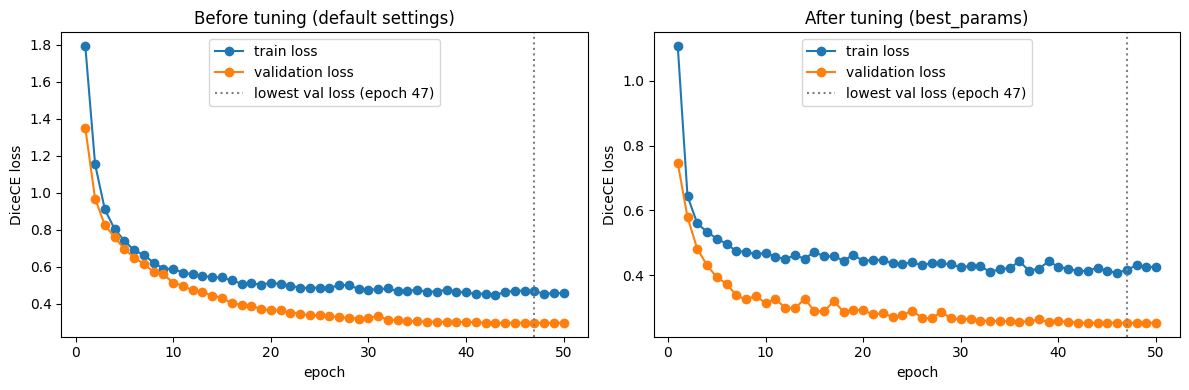

In [27]:
def plot_history(ax, history, title):
    epochs = range(1, len(history["train_loss"]) + 1)
    ax.plot(epochs, history["train_loss"], marker="o", label="train loss")
    ax.plot(epochs, history["val_loss"], marker="o", label="validation loss")
    best = int(np.argmin(history["val_loss"]))
    ax.axvline(best + 1, linestyle=":", color="gray", label=f"lowest val loss (epoch {best + 1})")
    ax.set_title(title); ax.set_xlabel("epoch"); ax.set_ylabel("DiceCE loss"); ax.legend()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_history(axes[0], baseline_default_history, "Before tuning (default settings)")
plot_history(axes[1], baseline_history, "After tuning (best_params)")
plt.tight_layout()
plt.show()

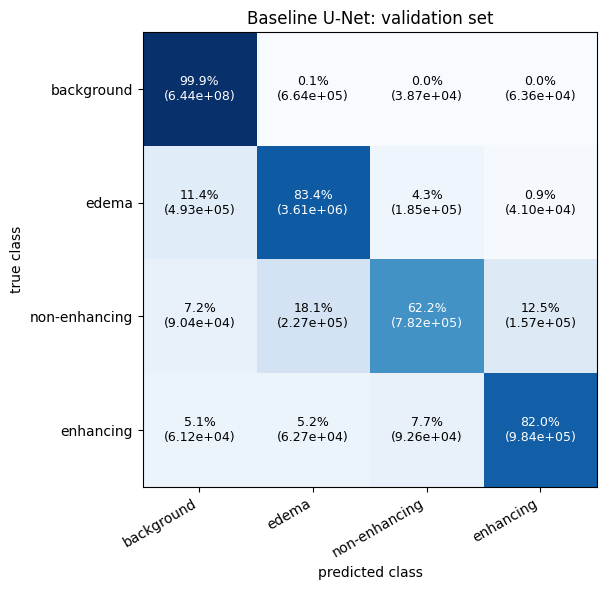

Baseline U-Net: scores pooled over all validation voxels
                   Dice     IoU  Precision  Recall
edema            0.8121  0.6837     0.7913  0.8341
non-enhancing    0.6642  0.4972     0.7120  0.6224
enhancing        0.8045  0.6730     0.7899  0.8196
WT               0.8970  0.8133     0.8891  0.9051
TC               0.8397  0.7238     0.8600  0.8204
ET               0.8045  0.6730     0.7899  0.8196


In [28]:
baseline_cm = confusion_matrix_voxels(baseline_model, val_loader)
plot_confusion(baseline_cm, "Baseline U-Net: validation set", "confusion_baseline.png")
with open("confusion_baseline.json", "w") as f:
    json.dump(baseline_cm.tolist(), f)
baseline_scores = report_metrics(baseline_cm, "Baseline U-Net", "metrics_baseline.json")

#### Attention U-Net

In [29]:
from monai.networks.nets import AttentionUnet

attention_model = AttentionUnet(
    spatial_dims=3,
    in_channels=4,
    out_channels=4,
    channels=(16, 32, 64, 128, 256),
    strides=(2, 2, 2, 2),
    dropout=DROPOUT,
).to(device)

In [30]:
attention_history = train_model(
    attention_model, train_loader, val_loader,
    num_epochs=50, run_name="attention", save_path="attention_last.pt", **train_kwargs
)

[attention] epoch 1/50 train_loss=1.1753 val_loss=1.0948
[attention] epoch 2/50 train_loss=0.9490 val_loss=0.9091
[attention] epoch 3/50 train_loss=0.8011 val_loss=0.7989
[attention] epoch 4/50 train_loss=0.7133 val_loss=0.7264
[attention] epoch 5/50 train_loss=0.6612 val_loss=0.6635
[attention] epoch 6/50 train_loss=0.6200 val_loss=0.6027
[attention] epoch 7/50 train_loss=0.5890 val_loss=0.5455
[attention] epoch 8/50 train_loss=0.5629 val_loss=0.5016
[attention] epoch 9/50 train_loss=0.5485 val_loss=0.4651
[attention] epoch 10/50 train_loss=0.5447 val_loss=0.4218
[attention] epoch 11/50 train_loss=0.5221 val_loss=0.4036
[attention] epoch 12/50 train_loss=0.5185 val_loss=0.3780
[attention] epoch 13/50 train_loss=0.5151 val_loss=0.3571
[attention] epoch 14/50 train_loss=0.4977 val_loss=0.3409
[attention] epoch 15/50 train_loss=0.4928 val_loss=0.3281
[attention] epoch 16/50 train_loss=0.5003 val_loss=0.3208
[attention] epoch 17/50 train_loss=0.4822 val_loss=0.3223
[attention] epoch 18/50

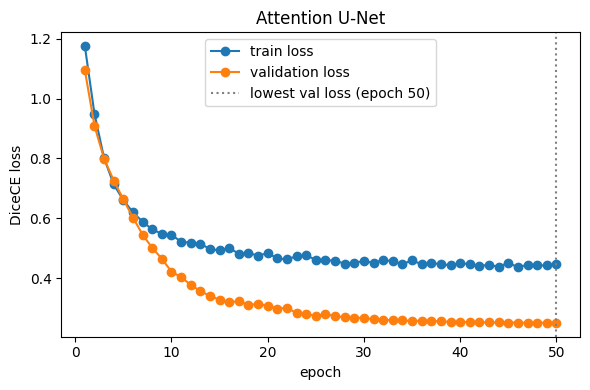

In [31]:
fig, ax = plt.subplots(figsize=(6, 4))
plot_history(ax, attention_history, "Attention U-Net")
plt.tight_layout()
plt.savefig("attention_curves.png", dpi=150)
plt.show()

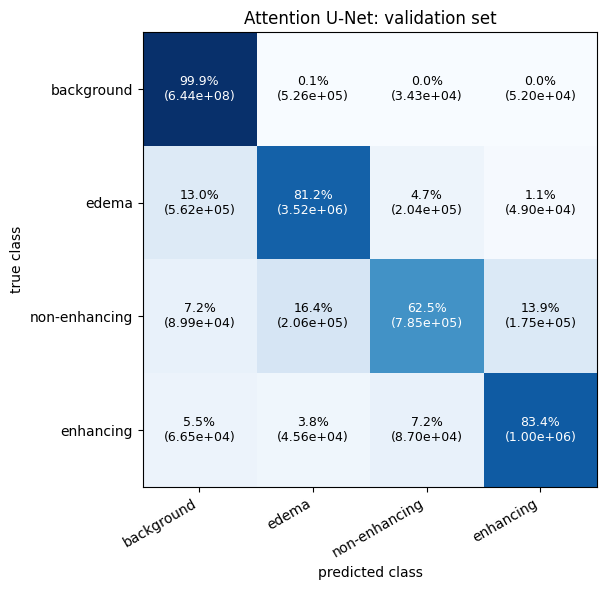

Attention U-Net: scores pooled over all validation voxels
                   Dice     IoU  Precision  Recall
edema            0.8154  0.6884     0.8189  0.8120
non-enhancing    0.6634  0.4963     0.7069  0.6249
enhancing        0.8083  0.6783     0.7840  0.8341
WT               0.9013  0.8203     0.9084  0.8942
TC               0.8456  0.7325     0.8578  0.8338
ET               0.8083  0.6783     0.7840  0.8341


In [32]:
attention_cm = confusion_matrix_voxels(attention_model, val_loader)
plot_confusion(attention_cm, "Attention U-Net: validation set", "confusion_attention.png")
with open("confusion_attention.json", "w") as f:
    json.dump(attention_cm.tolist(), f)
attention_scores = report_metrics(attention_cm, "Attention U-Net", "metrics_attention.json")

#### ResNet-34 encoder (MedicalNet weights) with a U-Net decoder

In [33]:
# builds the model and loads the pretrained weights
import torch.nn as nn
import torch.nn.functional as F
from monai.networks.nets.resnet import resnet34

def conv_block(c_in, c_out, dropout):
    return nn.Sequential(
        nn.Conv3d(c_in, c_out, 3, padding=1, bias=False), nn.InstanceNorm3d(c_out), nn.ReLU(inplace=True),
        nn.Dropout3d(dropout),   # switches off whole feature maps at random while training; does nothing when dropout=0
        nn.Conv3d(c_out, c_out, 3, padding=1, bias=False), nn.InstanceNorm3d(c_out), nn.ReLU(inplace=True),
    )

class ResNet34UNet(nn.Module):
    # MONAI 3D ResNet-34 as the encoder, U-Net style decoder
    def __init__(self, in_channels=4, out_channels=4, dropout=0.0, deep_supervision=False):
        super().__init__()
        self.deep_supervision = deep_supervision
        self.backbone = resnet34(
            pretrained=False, spatial_dims=3, n_input_channels=in_channels,
            conv1_t_stride=2,
            feed_forward=False, shortcut_type="A", bias_downsample=True,  # settings its ResNet-34 weights need
        )
        self.dec3 = conv_block(512 + 256, 256, dropout)
        self.dec2 = conv_block(256 + 128, 128, dropout)
        self.dec1 = conv_block(128 + 64, 64, dropout)
        self.dec0 = conv_block(64 + 64, 32, dropout)
        self.head = nn.Conv3d(32, out_channels, kernel_size=1)
        # extra 1x1x1 output layers on three decoder stages, used only for deep supervision
        self.aux3 = nn.Conv3d(256, out_channels, kernel_size=1)
        self.aux2 = nn.Conv3d(128, out_channels, kernel_size=1)
        self.aux1 = nn.Conv3d(64, out_channels, kernel_size=1)

    @staticmethod
    def _up_cat(x, skip):
        x = F.interpolate(x, size=skip.shape[2:], mode="trilinear", align_corners=False)
        return torch.cat([x, skip], dim=1)

    def forward(self, x):
        b = self.backbone
        s0 = b.act(b.bn1(b.conv1(x)))   # 1/2 size, 64 channels
        s1 = b.layer1(b.maxpool(s0))    # 1/4,  64
        s2 = b.layer2(s1)               # 1/8,  128
        s3 = b.layer3(s2)               # 1/16, 256
        s4 = b.layer4(s3)               # 1/32, 512
        d3 = self.dec3(self._up_cat(s4, s3))
        d2 = self.dec2(self._up_cat(d3, s2))
        d1 = self.dec1(self._up_cat(d2, s1))
        d0 = self.dec0(self._up_cat(d1, s0))
        size = x.shape[2:]
        main = F.interpolate(self.head(d0), size=size, mode="trilinear", align_corners=False)
        if self.deep_supervision and self.training:
            # training only: the main output first, then three extra outputs from deeper stages,
            # all enlarged to the full size so each can be compared with the label
            extra = [F.interpolate(head(d), size=size, mode="trilinear", align_corners=False)
                     for head, d in ((self.aux1, d1), (self.aux2, d2), (self.aux3, d3))]
            return [main] + extra
        return main

DEEP_SUPERVISION = True   # chosen setting; False trains this model with the main output only
UNFREEZE_AT_EPOCH = 15
medicalnet_model = ResNet34UNet(in_channels=4, out_channels=4, dropout=DROPOUT,
                                deep_supervision=DEEP_SUPERVISION).to(device)

# load the MedicalNet weights into the encoder
ckpt = torch.load("resnet_34_23dataset.pth", map_location=device)
pretrained_state = {k.replace("module.", "", 1): v for k, v in ckpt["state_dict"].items()}

# 4 MRI modalities but the pretrained first layer has 1 input channel: copy it to all 4 and divide by 4
pretrained_state["conv1.weight"] = pretrained_state["conv1.weight"].repeat(1, 4, 1, 1, 1) / 4

encoder_state_dict = medicalnet_model.backbone.state_dict()

# snapshot the encoder before loading, to prove afterwards that something changed
before = {k: v.clone() for k, v in encoder_state_dict.items()}

# strict=True: any missing, extra or wrongly shaped tensor raises an error here
medicalnet_model.backbone.load_state_dict(pretrained_state, strict=True)

print(f"Loaded {len(pretrained_state)} of {len(encoder_state_dict)} encoder tensors from MedicalNet")

# verify the weights really changed
after = medicalnet_model.backbone.state_dict()
changed = [k for k in after if not torch.equal(before[k], after[k])]

print(f"tensors actually changed: {len(changed)}")
print("example pretrained keys:", list(pretrained_state.keys())[:5])
print("example encoder keys:   ", list(after.keys())[:5])

if len(changed) == 0:
    raise RuntimeError("No pretrained weights were loaded. Do not train this model.")

Loaded 198 of 198 encoder tensors from MedicalNet
tensors actually changed: 198
example pretrained keys: ['conv1.weight', 'bn1.weight', 'bn1.bias', 'bn1.running_mean', 'bn1.running_var']
example encoder keys:    ['conv1.weight', 'bn1.weight', 'bn1.bias', 'bn1.running_mean', 'bn1.running_var']


In [34]:
def fresh_medicalnet():
    # the same model, with the pretrained encoder weights loaded again
    model = ResNet34UNet(in_channels=4, out_channels=4, dropout=DROPOUT,
                         deep_supervision=DEEP_SUPERVISION).to(device)
    model.backbone.load_state_dict(pretrained_state, strict=True)
    return model

UNFREEZE_EPOCHS = 15                      # length of each comparison run
UNFREEZE_OPTIONS = [0, 5, 10, None]    # epochs frozen; 0 = never frozen, None = frozen the whole run

def run_unfreeze(unfreeze_at):
    model = fresh_medicalnet()
    train_model(model, train_loader, tune_val_loader, num_epochs=UNFREEZE_EPOCHS,
                run_name=f"unfreeze_{unfreeze_at}",
                freeze_params=list(model.backbone.parameters()), unfreeze_at_epoch=unfreeze_at,
                deep_supervision=DEEP_SUPERVISION, **train_kwargs)
    return evaluate_model(model, tune_val_loader)["mean_dice"]

unfreeze_results, best_unfreeze = run_option_search(UNFREEZE_OPTIONS, run_unfreeze, "unfreeze_results.jsonl")
UNFREEZE_AT_EPOCH = None if best_unfreeze == "None" else int(best_unfreeze)
print("UNFREEZE_AT_EPOCH =", UNFREEZE_AT_EPOCH)

[unfreeze_0] epoch 1: unfreezing 99 parameter tensors
[unfreeze_0] epoch 1/15 train_loss=2.0073 val_loss=1.0077
[unfreeze_0] epoch 2/15 train_loss=1.4513 val_loss=0.8078
[unfreeze_0] epoch 3/15 train_loss=1.2304 val_loss=0.7024
[unfreeze_0] epoch 4/15 train_loss=1.1267 val_loss=0.6487
[unfreeze_0] epoch 5/15 train_loss=1.0527 val_loss=0.5886
[unfreeze_0] epoch 6/15 train_loss=1.0000 val_loss=0.5384
[unfreeze_0] epoch 7/15 train_loss=0.9979 val_loss=0.5056
[unfreeze_0] epoch 8/15 train_loss=0.9544 val_loss=0.4754
[unfreeze_0] epoch 9/15 train_loss=0.9342 val_loss=0.4611
[unfreeze_0] epoch 10/15 train_loss=0.9317 val_loss=0.4408
[unfreeze_0] epoch 11/15 train_loss=0.9144 val_loss=0.4248
[unfreeze_0] epoch 12/15 train_loss=0.9110 val_loss=0.4192
[unfreeze_0] epoch 13/15 train_loss=0.8979 val_loss=0.4117
[unfreeze_0] epoch 14/15 train_loss=0.8742 val_loss=0.4062
[unfreeze_0] epoch 15/15 train_loss=0.8744 val_loss=0.4057
option 0: mean Dice 0.8002 in 1503 s
[unfreeze_5] epoch 1/15 train_los

In [35]:
"""
The encoder block is frozen and unfrozen automatically,
this preserves the pretrained weights and prevent them from being updated
during the initial training stage.
"""
medicalnet_history = train_model(
    medicalnet_model, train_loader, val_loader,
    num_epochs=50, run_name="medicalnet", save_path="medicalnet_last.pt",
    freeze_params=list(medicalnet_model.backbone.parameters()), unfreeze_at_epoch=UNFREEZE_AT_EPOCH,
    deep_supervision=DEEP_SUPERVISION,
    **train_kwargs
)

[medicalnet] epoch 1: unfreezing 99 parameter tensors
[medicalnet] epoch 1/50 train_loss=1.9153 val_loss=0.9190
[medicalnet] epoch 2/50 train_loss=1.3857 val_loss=0.7671
[medicalnet] epoch 3/50 train_loss=1.2182 val_loss=0.6874
[medicalnet] epoch 4/50 train_loss=1.1174 val_loss=0.6127
[medicalnet] epoch 5/50 train_loss=1.0534 val_loss=0.5674
[medicalnet] epoch 6/50 train_loss=1.0151 val_loss=0.5147
[medicalnet] epoch 7/50 train_loss=1.0014 val_loss=0.4910
[medicalnet] epoch 8/50 train_loss=0.9406 val_loss=0.4365
[medicalnet] epoch 9/50 train_loss=0.9480 val_loss=0.4167
[medicalnet] epoch 10/50 train_loss=0.9251 val_loss=0.3966
[medicalnet] epoch 11/50 train_loss=0.9329 val_loss=0.3795
[medicalnet] epoch 12/50 train_loss=0.9041 val_loss=0.3602
[medicalnet] epoch 13/50 train_loss=0.9013 val_loss=0.3521
[medicalnet] epoch 14/50 train_loss=0.8769 val_loss=0.3498
[medicalnet] epoch 15/50 train_loss=0.8934 val_loss=0.3318
[medicalnet] epoch 16/50 train_loss=0.8571 val_loss=0.3185
[medicalnet

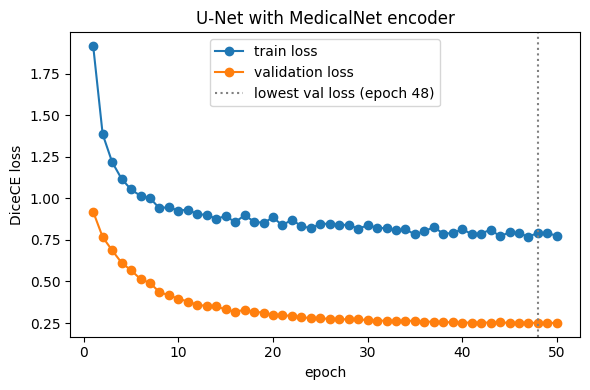

In [36]:
fig, ax = plt.subplots(figsize=(6, 4))
plot_history(ax, medicalnet_history, "U-Net with MedicalNet encoder")
plt.tight_layout()
plt.savefig("medicalnet_curves.png", dpi=150)
plt.show()

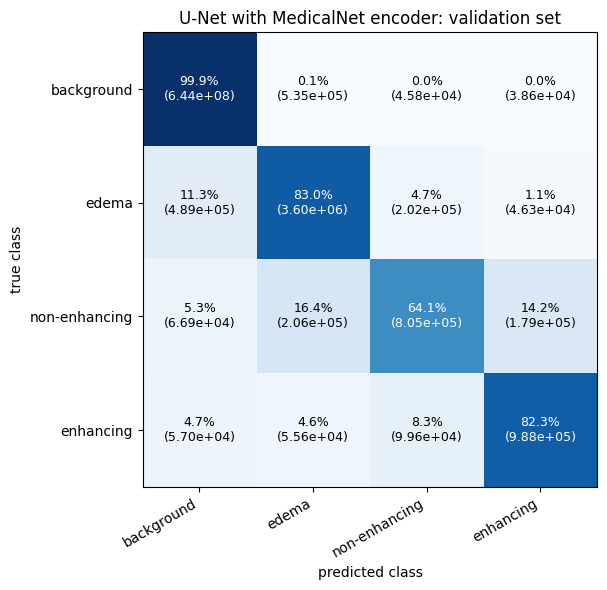

U-Net with MedicalNet encoder: scores pooled over all validation voxels
                   Dice     IoU  Precision  Recall
edema            0.8244  0.7012     0.8188  0.8300
non-enhancing    0.6684  0.5020     0.6987  0.6407
enhancing        0.8059  0.6749     0.7893  0.8232
WT               0.9093  0.8337     0.9089  0.9097
TC               0.8524  0.7428     0.8617  0.8432
ET               0.8059  0.6749     0.7893  0.8232


In [37]:
medicalnet_cm = confusion_matrix_voxels(medicalnet_model, val_loader)
plot_confusion(medicalnet_cm, "U-Net with MedicalNet encoder: validation set", "confusion_medicalnet.png")
with open("confusion_medicalnet.json", "w") as f:
    json.dump(medicalnet_cm.tolist(), f)
medicalnet_scores = report_metrics(medicalnet_cm, "U-Net with MedicalNet encoder", "metrics_medicalnet.json")

#### Compare on validation

In [38]:
models = {
    "baseline": baseline_model,
    "attention": attention_model,
    "medicalnet": medicalnet_model,
}

comparison_results = {}
for name, model in models.items():
    scores = evaluate_model(model, val_loader)
    comparison_results[name] = scores
    print(f"{name}: mean_dice={scores['mean_dice']:.4f}")

# validation-based comparison only
import json
with open("model_comparison.json", "w") as f:
    json.dump(comparison_results, f, indent=2)

baseline: mean_dice=0.8056
attention: mean_dice=0.8108
medicalnet: mean_dice=0.8134


#### One time evaluation on the held out test set

In [39]:
best_model_name = max(comparison_results, key=lambda k: comparison_results[k]["mean_dice"])
best_model = models[best_model_name]
print(f"Best model on validation: {best_model_name}")

# evaluation on the held-out test set
final_test_scores = evaluate_model(best_model, test_loader)
print(f"Final TEST set performance ({best_model_name}): "
      f"mean_dice={final_test_scores['mean_dice']:.4f}")

Best model on validation: medicalnet
Final TEST set performance (medicalnet): mean_dice=0.7989


#### Prediction overlay

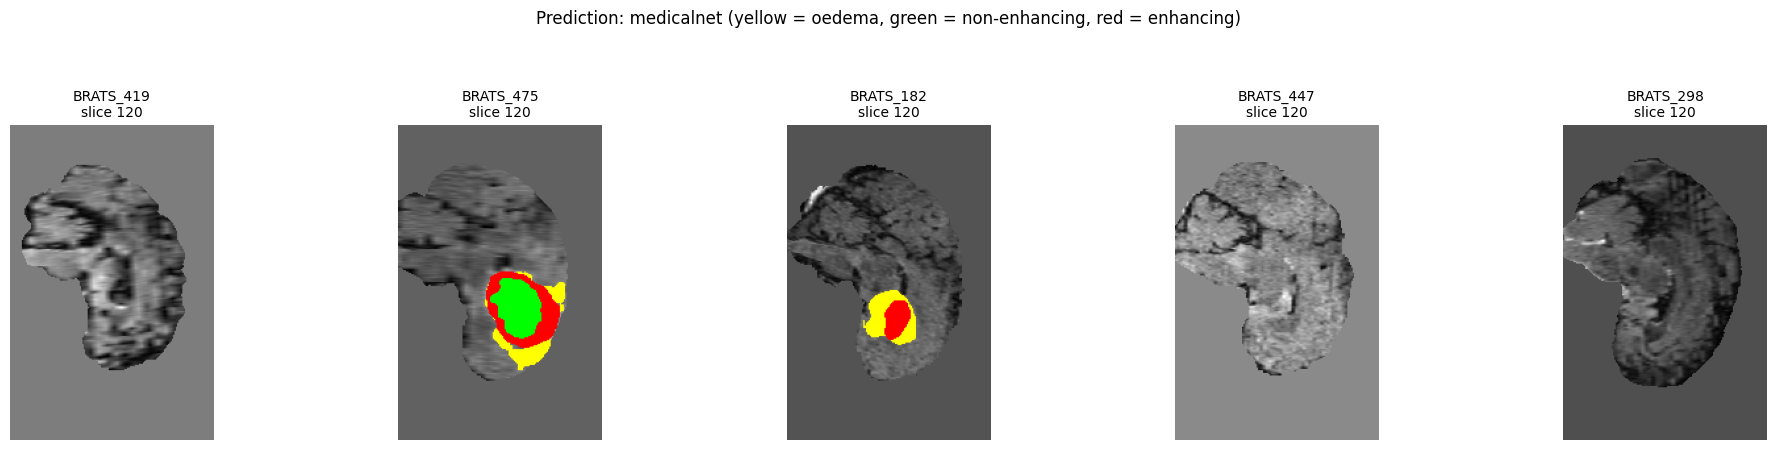

In [40]:
N_SHOW = 5

# class -> display colour (order verified against dataset.json "labels")
colour_map = {
    0: (0, 0, 0),
    1: (255, 255, 0),   # Oedema
    2: (0, 255, 0),     # Non-Enhancing Tumour
    3: (255, 0, 0),     # Enhancing Tumour (ET)
}

fig, axes = plt.subplots(1, N_SHOW, figsize=(4 * N_SHOW, 4.5))
best_model.eval()
for n in range(N_SHOW):
    sample = test_ds[n]
    inputs = sample["image"].unsqueeze(0).to(device)

    with torch.no_grad():
        output = sliding_window_inference(inputs, (96, 96, 96), 4, best_model)
        prediction = torch.argmax(output, dim=1)[0].cpu()

    slice_idx = prediction.shape[0] // 2
    grayscale_slice = inputs[0, 0, slice_idx].cpu().numpy()
    pred_slice = prediction[slice_idx].numpy()

    overlay = np.stack([grayscale_slice] * 3, axis=-1)
    overlay = (overlay - overlay.min()) / (overlay.max() - overlay.min() + 1e-8)
    for class_id, colour in colour_map.items():
        if class_id == 0:
            continue
        mask = pred_slice == class_id
        for c in range(3):
            overlay[..., c][mask] = colour[c] / 255.0

    axes[n].imshow(overlay)
    axes[n].set_title(f"{test_ids[n]}\nslice {slice_idx}", fontsize=10)
    axes[n].axis("off")

fig.suptitle(f"Prediction: {best_model_name} (yellow = oedema, green = non-enhancing, red = enhancing)", y=0.99)
plt.tight_layout(rect=(0, 0, 1, 0.92))
plt.savefig("prediction_overlay_5_patients.png", dpi=150)
plt.show()